In [27]:
import torch
import torch.nn as nn

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cpu


In [29]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

dataset = datasets.ImageFolder(
    root="../data/images",
    transform=transform
)

In [30]:
class_names = dataset.classes

In [31]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

                            precision    recall  f1-score   support

              aerosol_cans       0.95      0.95      0.95        79
        aluminum_food_cans       0.57      0.50      0.53        80
        aluminum_soda_cans       0.83      0.79      0.81        80
           cardboard_boxes       0.48      0.68      0.56        72
       cardboard_packaging       0.53      0.41      0.46        80
                  clothing       0.84      0.88      0.86        72
            coffee_grounds       0.97      0.97      0.97        76
disposable_plastic_cutlery       0.98      0.97      0.98        67
                 eggshells       0.98      0.91      0.95        68
                food_waste       0.95      1.00      0.98        60
    glass_beverage_bottles       0.92      0.91      0.92        91
 glass_cosmetic_containers       0.94      0.94      0.94        65
           glass_food_jars       0.85      0.91      0.88        55
                 magazines       0.92      0.93

In [32]:
train_size = int(0.7 * len(dataset))
val_size = int(0.15 * len(dataset))
test_size = len(dataset) - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

In [33]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [ ]:
# Load ResNet50 architecture
weights = models.ResNet50_Weights.DEFAULT
model = models.resnet50(weights=weights)

# Replace the final layer
num_classes = len(dataset.classes)

model.fc = nn.Linear(
    model.fc.in_features,
    num_classes
)

# Load the trained weights
model.load_state_dict(
    torch.load("../models/resnet50_best.pth", map_location=device)
)

model = model.to(device)
model.eval()

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

print("Model loaded successfully!")

Model loaded successfully!


In [35]:
all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

print("Testing complete!")

Testing complete!


In [36]:
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {accuracy*100:.2f}%")

Test Accuracy: 85.73%


In [37]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=class_names
))

                            precision    recall  f1-score   support

              aerosol_cans       0.95      0.95      0.95        79
        aluminum_food_cans       0.57      0.50      0.53        80
        aluminum_soda_cans       0.83      0.79      0.81        80
           cardboard_boxes       0.48      0.68      0.56        72
       cardboard_packaging       0.53      0.41      0.46        80
                  clothing       0.84      0.88      0.86        72
            coffee_grounds       0.97      0.97      0.97        76
disposable_plastic_cutlery       0.98      0.97      0.98        67
                 eggshells       0.98      0.91      0.95        68
                food_waste       0.95      1.00      0.98        60
    glass_beverage_bottles       0.92      0.91      0.92        91
 glass_cosmetic_containers       0.94      0.94      0.94        65
           glass_food_jars       0.85      0.91      0.88        55
                 magazines       0.92      0.93

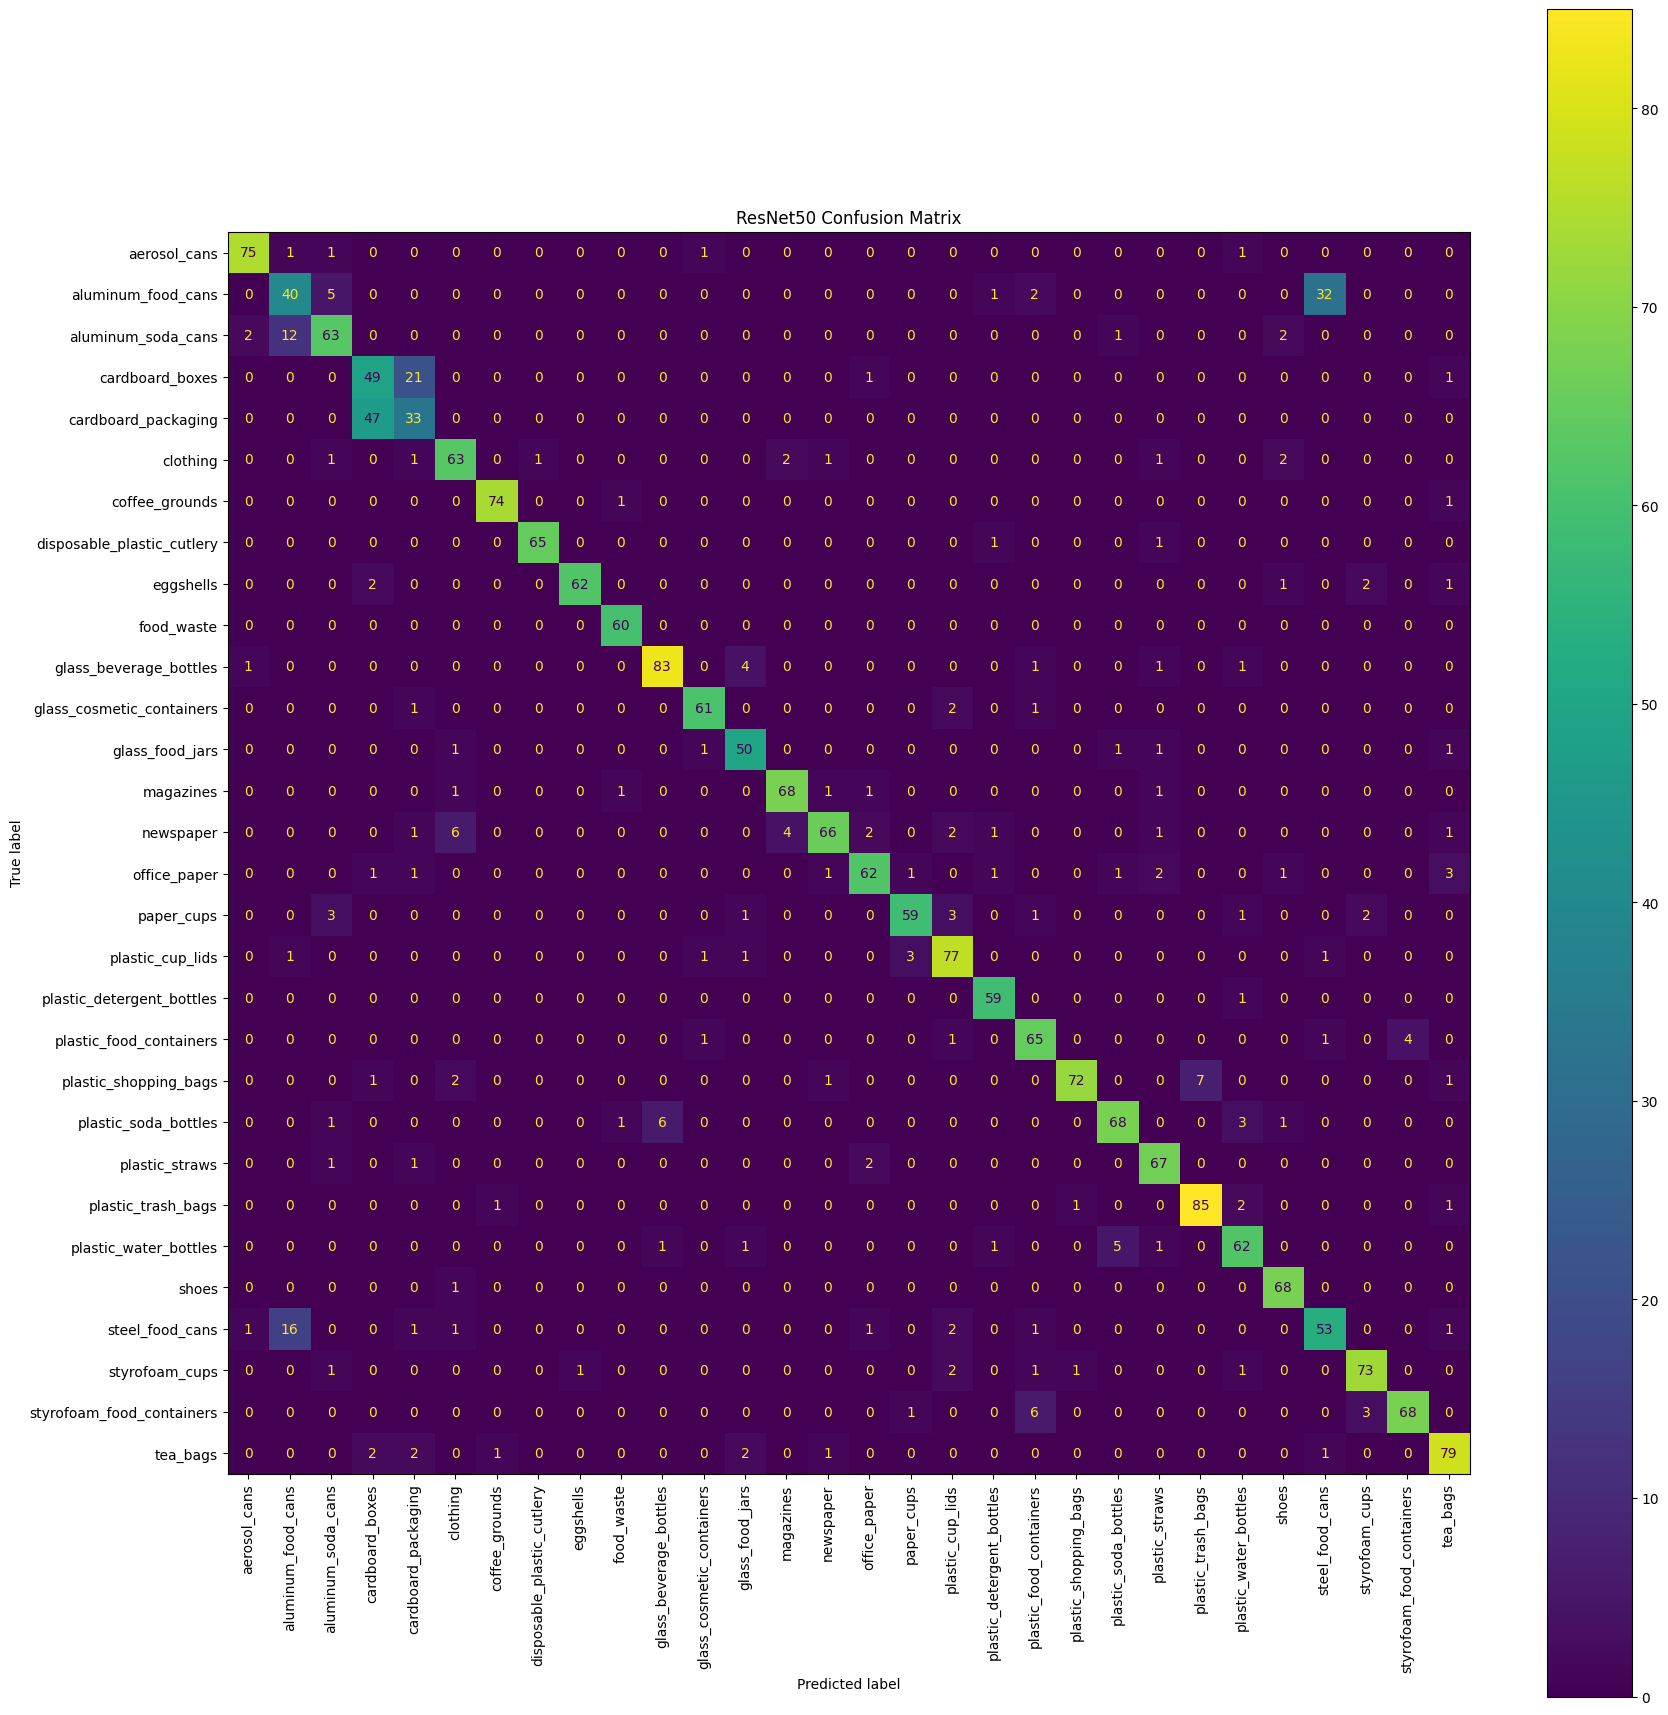

In [38]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(ax=ax, xticks_rotation=90)

plt.title("ResNet50 Confusion Matrix")
plt.tight_layout()

plt.savefig("../results/resnet50_confusion_matrix.png")

plt.show()

In [39]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=dataset.classes
)

with open("../results/resnet50_classification_report.txt", "w") as f:
    f.write(report)

print("Classification report saved successfully!")

Classification report saved successfully!


In [40]:
print(class_names)

['aerosol_cans', 'aluminum_food_cans', 'aluminum_soda_cans', 'cardboard_boxes', 'cardboard_packaging', 'clothing', 'coffee_grounds', 'disposable_plastic_cutlery', 'eggshells', 'food_waste', 'glass_beverage_bottles', 'glass_cosmetic_containers', 'glass_food_jars', 'magazines', 'newspaper', 'office_paper', 'paper_cups', 'plastic_cup_lids', 'plastic_detergent_bottles', 'plastic_food_containers', 'plastic_shopping_bags', 'plastic_soda_bottles', 'plastic_straws', 'plastic_trash_bags', 'plastic_water_bottles', 'shoes', 'steel_food_cans', 'styrofoam_cups', 'styrofoam_food_containers', 'tea_bags']
